# Simulação Five-Spot 2D

Modelo monofásico heterogêneo totalmente implícito, com quatro injetores de vazão prescrita nos cantos e um produtor central de pressão prescrita. As fronteiras externas têm fluxo nulo. O arranjo segue a Aula 12 e as equações de poço da Aula 11.

Produtor (i, j) = (10, 10) | Pwf = 15.0 MPa
Injetores (i, j) = [(0, 0), (20, 0), (0, 20), (20, 20)]
Vazão de injeção por poço = 0.0093 m³/s
Vazão final do produtor = -0.03964084488887656 m³/s (negativa indica produção)


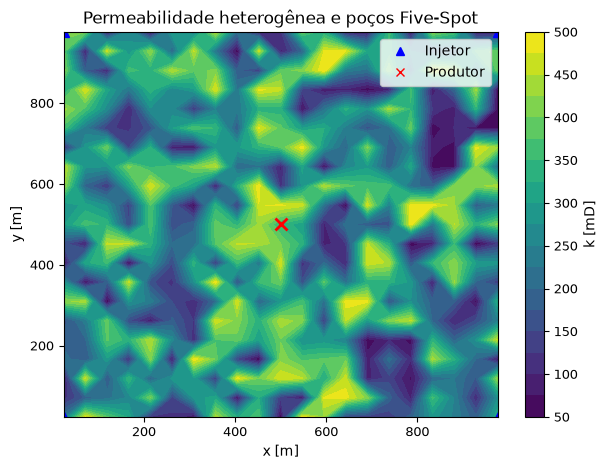

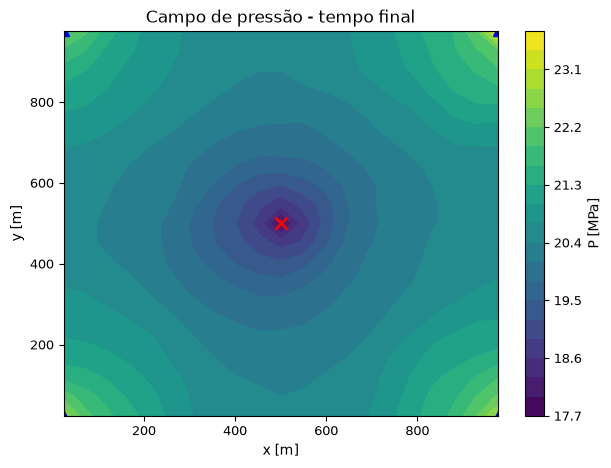

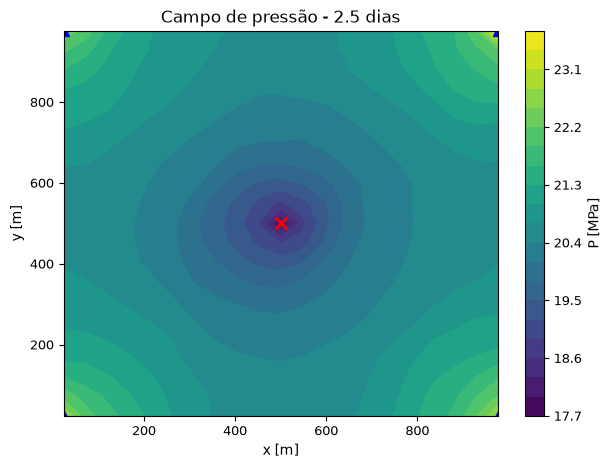

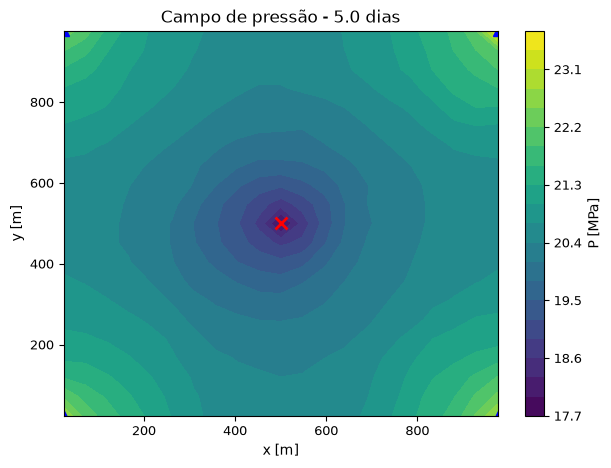

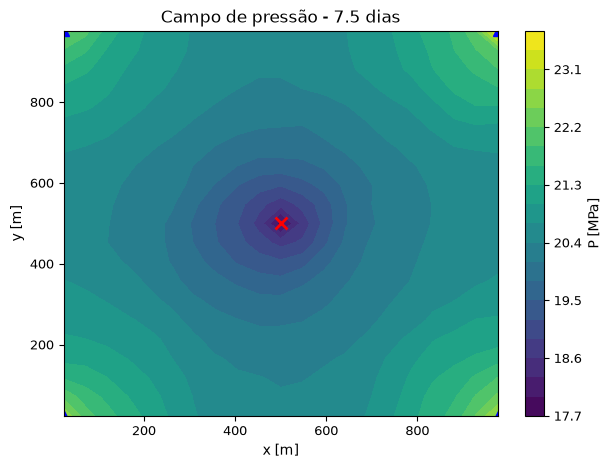

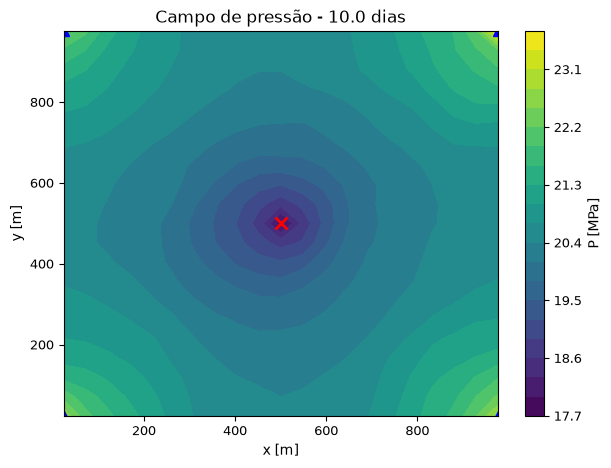

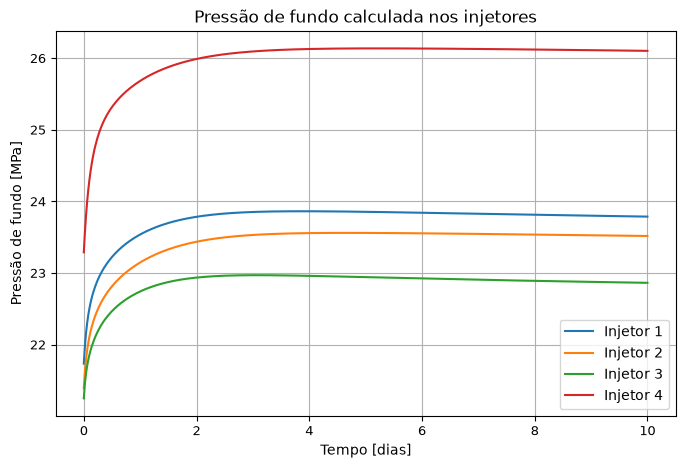

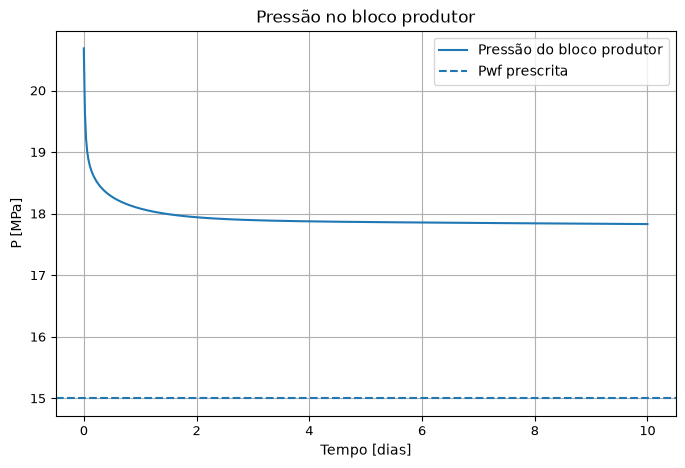

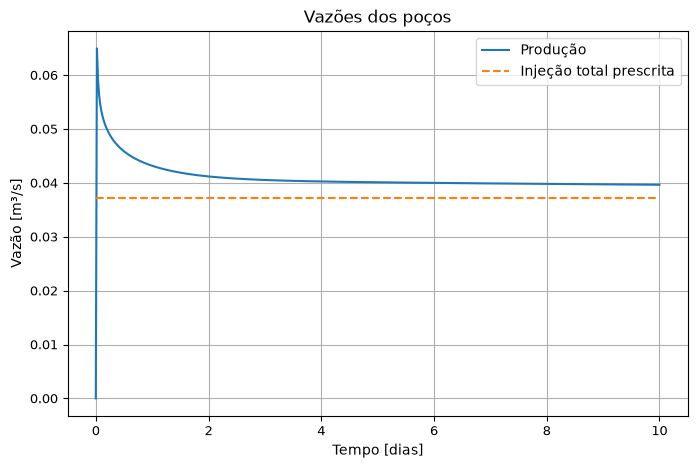

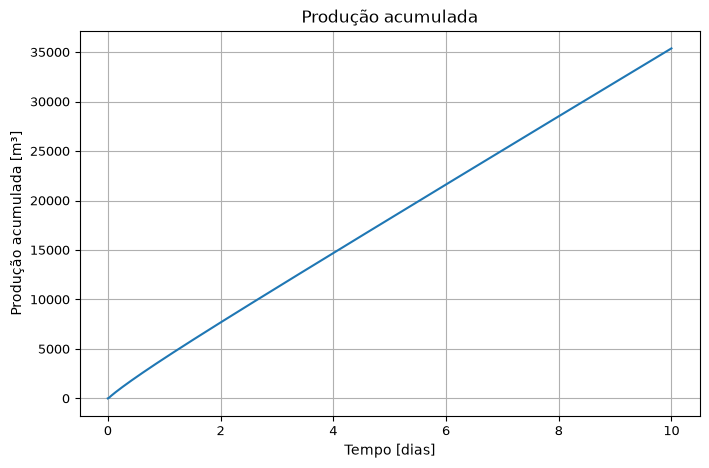

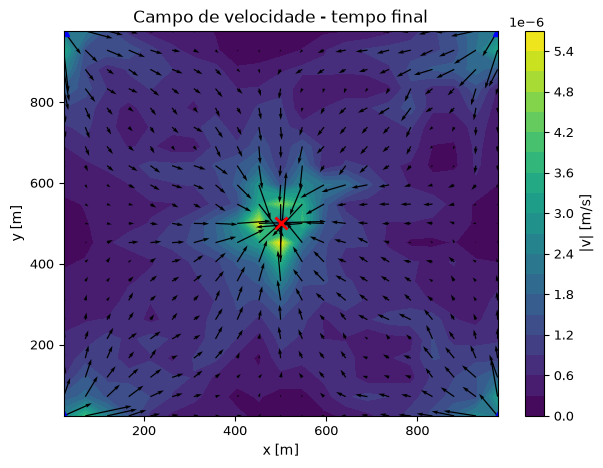

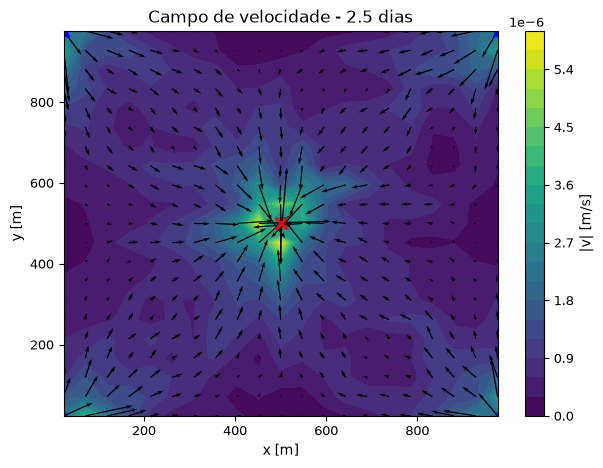

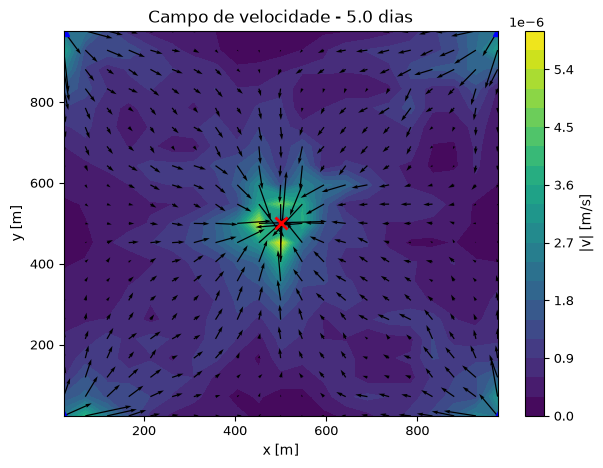

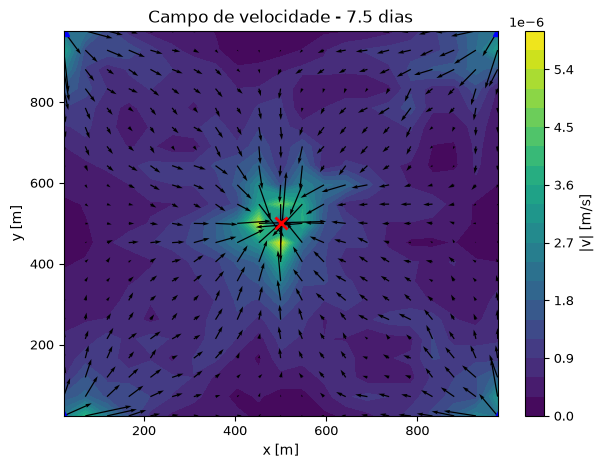

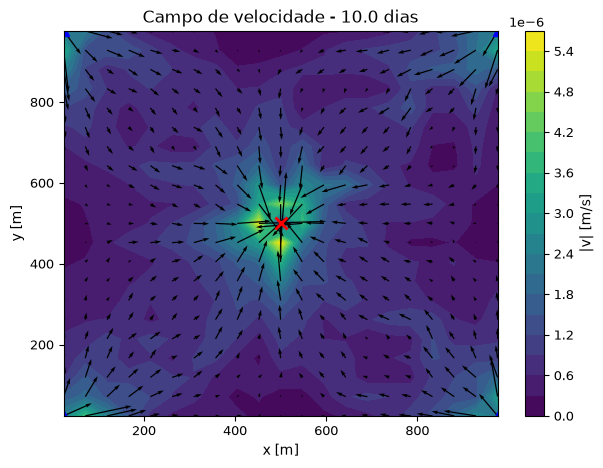

In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 10, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from mdf.implicita_2d import implicita_2d
from core.peaceman import raio_equivalente, well_index, pressao_vazao_prescrita
from core.permeabilidade2d import carregar_permeabilidade
from core.velocidade2d import calcular_velocidade

_figura_id = 0
def salvar_e_mostrar():
    global _figura_id
    _figura_id += 1
    plt.savefig(RESULTS_DIR / f"five_spot_{_figura_id:02d}.pdf", dpi=180, bbox_inches="tight")
    plt.show()


p0 = 20.684e6
pwf = 15.0e6
q_injecao_total = 3.72e-2
Lx = 1000.0
Ly = 1000.0
h = 30.0
rw = 0.10
phi = 0.22
ct = 3.046e-9
mu = 1.0e-3
t_d = 10
t_final = t_d * 86400


nx = 21
ny = 21
nt = 500
dx = Lx / nx
dy = Ly / ny


k_mD = carregar_permeabilidade(ROOT / "data" / "permeabilidade.csv")
k = k_mD * 9.869233e-16


injetores = [
    {"i": 0, "j": 0, "rate": q_injecao_total / 4},
    {"i": nx - 1, "j": 0, "rate": q_injecao_total / 4},
    {"i": 0, "j": ny - 1, "rate": q_injecao_total / 4},
    {"i": nx - 1, "j": ny - 1, "rate": q_injecao_total / 4},
]
iw, jw = nx // 2, ny // 2


x, y, t, P, q_produtor = implicita_2d(
    p0, pwf, rw, h, Lx, Ly, k, phi, ct, mu, t_final, nx, ny, nt,
    iw=iw, jw=jw, injection_wells=injetores,
)
q_producao = np.maximum(-q_produtor, 0.0)



req = raio_equivalente(dx)
WI = well_index(req, rw, h)
pwf_injetores = {}
for n, poco in enumerate(injetores, start=1):
    i, j, q = poco["i"], poco["j"], poco["rate"]
    pwf_injetores[n] = pressao_vazao_prescrita(q, P[:, j, i], k[j, i], mu, WI)

print("Produtor (i, j) =", (iw, jw), "| Pwf =", pwf / 1e6, "MPa")
print("Injetores (i, j) =", [(p["i"], p["j"]) for p in injetores])
print("Vazão de injeção por poço =", injetores[0]["rate"], "m³/s")
print("Vazão final do produtor =", q_produtor[-1], "m³/s (negativa indica produção)")

X, Y = np.meshgrid(x, y)
def marcar_pocos():
    for poco in injetores:
        plt.plot(x[poco["i"]], y[poco["j"]], "b^", markersize=7)
    plt.plot(x[iw], y[jw], "rx", markersize=9, mew=2)


plt.figure(figsize=(7, 5))
mapa = plt.contourf(X, Y, k_mD, levels=20, cmap="viridis")
plt.colorbar(mapa, label="k [mD]")
marcar_pocos()
plt.xlabel("x [m]"); plt.ylabel("y [m]")
plt.title("Permeabilidade heterogênea e poços Five-Spot")
plt.plot([], [], "b^", label="Injetor"); plt.plot([], [], "rx", label="Produtor"); plt.legend()
salvar_e_mostrar()


plt.figure(figsize=(7, 5))
contorno = plt.contourf(X, Y, P[-1] / 1e6, levels=20, cmap="viridis")
plt.colorbar(contorno, label="P [MPa]")
marcar_pocos()
plt.xlabel("x [m]"); plt.ylabel("y [m]"); plt.title("Campo de pressão - tempo final")
salvar_e_mostrar()


tempos = np.linspace(t_d / 4, t_d, 4)
for tempo in tempos:
    indice = np.argmin(np.abs(t - tempo * 86400))
    plt.figure(figsize=(7, 5))
    contorno = plt.contourf(X, Y, P[indice] / 1e6, levels=20, cmap="viridis")
    plt.colorbar(contorno, label="P [MPa]")
    marcar_pocos()
    plt.xlabel("x [m]"); plt.ylabel("y [m]"); plt.title(f"Campo de pressão - {tempo:.1f} dias")
    salvar_e_mostrar()


plt.figure(figsize=(8, 5))
for n, pressao in pwf_injetores.items():
    plt.plot(t / 86400, pressao / 1e6, label=f"Injetor {n}")
plt.xlabel("Tempo [dias]"); plt.ylabel("Pressão de fundo [MPa]")
plt.title("Pressão de fundo calculada nos injetores")
plt.grid(); plt.legend(); salvar_e_mostrar()


plt.figure(figsize=(8, 5))
plt.plot(t / 86400, P[:, jw, iw] / 1e6, label="Pressão do bloco produtor")
plt.axhline(pwf / 1e6, linestyle="--", label="Pwf prescrita")
plt.xlabel("Tempo [dias]"); plt.ylabel("P [MPa]"); plt.title("Pressão no bloco produtor")
plt.grid(); plt.legend(); salvar_e_mostrar()

plt.figure(figsize=(8, 5))
plt.plot(t / 86400, q_producao, label="Produção")
plt.plot(t / 86400, np.full_like(t, q_injecao_total), "--", label="Injeção total prescrita")
plt.xlabel("Tempo [dias]"); plt.ylabel("Vazão [m³/s]"); plt.title("Vazões dos poços")
plt.grid(); plt.legend(); salvar_e_mostrar()


Q_acumulada = np.zeros_like(t)
Q_acumulada[1:] = np.cumsum(0.5 * (q_producao[:-1] + q_producao[1:]) * np.diff(t))
plt.figure(figsize=(8, 5))
plt.plot(t / 86400, Q_acumulada)
plt.xlabel("Tempo [dias]"); plt.ylabel("Produção acumulada [m³]"); plt.title("Produção acumulada")
plt.grid(); salvar_e_mostrar()


Vx, Vy, V = calcular_velocidade(P, k, mu, dx, dy)
plt.figure(figsize=(7, 5))
velocidade = plt.contourf(X, Y, V[-1], levels=20, cmap="viridis")
plt.colorbar(velocidade, label="|v| [m/s]"); plt.quiver(X, Y, Vx[-1], Vy[-1]); marcar_pocos()
plt.xlabel("x [m]"); plt.ylabel("y [m]"); plt.title("Campo de velocidade - tempo final")
salvar_e_mostrar()

for tempo in tempos:
    indice = np.argmin(np.abs(t - tempo * 86400))
    plt.figure(figsize=(7, 5))
    velocidade = plt.contourf(X, Y, V[indice], levels=20, cmap="viridis")
    plt.colorbar(velocidade, label="|v| [m/s]"); plt.quiver(X, Y, Vx[indice], Vy[indice]); marcar_pocos()
    plt.xlabel("x [m]"); plt.ylabel("y [m]"); plt.title(f"Campo de velocidade - {tempo:.1f} dias")
    salvar_e_mostrar()


fig, ax = plt.subplots(figsize=(7, 5))
levels = np.linspace(np.min(P[1:] / 1e6), np.max(P[1:] / 1e6), 20)
def atualizar(frame):
    ax.clear()
    ax.contourf(X, Y, P[frame] / 1e6, levels=levels, cmap="viridis")
    for poco in injetores:
        ax.plot(x[poco["i"]], y[poco["j"]], "b^")
    ax.plot(x[iw], y[jw], "rx")
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    ax.set_title(f"Campo de pressão - {t[frame] / 86400:.2f} dias")
frames = np.linspace(1, len(t) - 1, 100, dtype=int)
animacao = FuncAnimation(fig, atualizar, frames=frames, interval=100)
plt.close()
HTML(animacao.to_jshtml())


Maior resíduo absoluto por passo: 1.777885e-10 m³
Resíduo global ao final: -8.824570e-09 m³
Variação armazenada ao final: -3.268316e+03 m³
Volume líquido acumulado: -3.268316e+03 m³


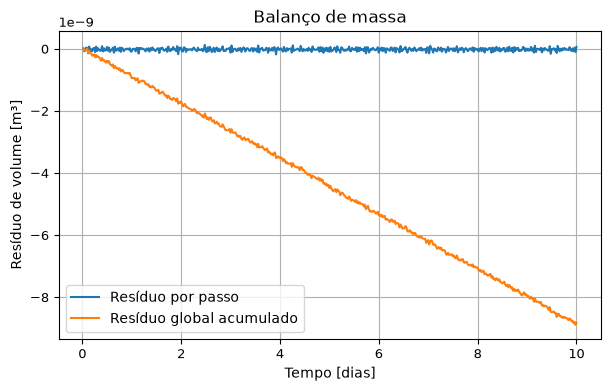

In [2]:
# Balanço de massa por passo e acumulado
# Vazões positivas entram no reservatório; q_produtor é negativo para produção.
volume_celula = (Lx / nx) * (Ly / ny) * h
armazenamento = phi * ct * volume_celula * (P.sum(axis=(1, 2)) - P[0].sum())
vazao_injecao = sum(poco["rate"] for poco in injetores)
vazao_liquida = vazao_injecao + q_produtor
dt_passos = np.diff(t)
volume_liquido_passo = vazao_liquida[1:] * dt_passos
variacao_armazenada_passo = np.diff(armazenamento)
residuo_passo = variacao_armazenada_passo - volume_liquido_passo
residuo_global = np.cumsum(residuo_passo)

print(f"Maior resíduo absoluto por passo: {np.max(np.abs(residuo_passo)):.6e} m³")
print(f"Resíduo global ao final: {residuo_global[-1]:.6e} m³")
print(f"Variação armazenada ao final: {armazenamento[-1]:.6e} m³")
print(f"Volume líquido acumulado: {np.sum(volume_liquido_passo):.6e} m³")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t[1:] / 86400, residuo_passo, label="Resíduo por passo")
ax.plot(t[1:] / 86400, residuo_global, label="Resíduo global acumulado")
ax.set(xlabel="Tempo [dias]", ylabel="Resíduo de volume [m³]", title="Balanço de massa")
ax.grid()
ax.legend()
plt.show()
